# Vezba 2

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### Konstatnte

In [2]:
SEED = 42
rng = np.random.default_rng(SEED)
sigma_sb = 5.670374419e-8     # W m^-2 K^-4   bolcmanova konstanta
L_sun = 3.828e26              # W             luminoznost Sunca
T_sun = 5772.0                # K             eff temperatura Sunca
S_sun = 1361                  # W/m           fluks sunca na zemlji (solarna konstanta) 
AU = 1.495978707e11           # m             au u metrima 
F_earth = L_sun / (4 * np.pi * AU**2)   #     fluks na zemlji

### Ulazni podaci i koeficijenti

In [3]:
# Kolone R, T i a izražene su u R_sun, K i AU.
# err kolone predstavljaju 1-sigma neizvesnosti (sintetički podaci).
candidates = pd.DataFrame([
    dict(name='Kandidat A', R=0.90, R_err=0.04, T=5400, T_err=100, a=0.90, a_err=0.03),
    dict(name='Kandidat B', R=0.75, R_err=0.05, T=4700, T_err=120, a=0.55, a_err=0.04),
    dict(name='Kandidat C', R=1.05, R_err=0.06, T=5900, T_err=150, a=1.55, a_err=np.nan),
])

# Redosled koeficijenata: S0, alpha, beta, gamma, delta
hz_coeff = {
    'RV': (1.776, 2.136e-4, 2.533e-8, -1.332e-11, -3.097e-15),
    'RG': (1.107, 1.332e-4, 1.580e-8, -8.308e-12, -1.931e-15),
    'MG': (0.356, 6.171e-5, 1.698e-9, -3.198e-12, -5.575e-16),
    'EM': (0.320, 5.547e-5, 1.526e-9, -2.874e-12, -5.011e-16),
}

display(candidates)

,name,R,R_err,T,T_err,a,a_err
0,Kandidat A,0.90,0.04,5400,100,0.90,0.03
1,Kandidat B,0.75,0.05,4700,120,0.55,0.04
2,Kandidat C,1.05,0.06,5900,150,1.55,NaN


## Zadatak 1

In [7]:
def stellar_luminosity(R,T):       # vraca luminoznost L
    R_sun = 1
    return (R / R_sun)**2 * (T / T_sun)**4
    
def incident_flux(L,a):            # vraca upadni fluks S
    return L / (a**2)

def equilibrium_temperature(S,A):  # vraca ravnoteznu temperaturu T
    A = np.array(A)
    F = S * S_sun 
    T = (F*(1-A) / (4*sigma_sb))**0.25
    return T

# Ulazni parametri iz zadatka
R = 0.90
T = 5400.0
a = 0.90
A = [0.1, 0.3, 0.6]

# Izračunavanje
L = stellar_luminosity(R, T)
S = incident_flux(L, a)
T_eq = equilibrium_temperature(S, A)

print(f"Luminoznost (L): {L:.4f} L_sun")
print(f"Upadni fluks (S): {S:.4f} S_earth")
print(f"Ravnotežne temperature (T_eq) za albeda {A}: {T_eq} K")    

Luminoznost (L): 0.6205 L_sun
Upadni fluks (S): 0.7661 S_earth
Ravnotežne temperature (T_eq) za albeda [0.1, 0.3, 0.6]: [253.61484108 238.17081716 207.07565061] K


## Zadatak 2

In [14]:
def effective_flux(T, boundary):      # vraca S_eff
    if boundary not in hz_coeff:
        raise ValueError(f"Nepoznata granica: {boundary}")   
    T_star = T - 5780.0               # Referentna temperatura Sunca
    S0, alpha, beta, gamma, delta = hz_coeff[boundary]
    Seff = S0 + alpha * T_star + beta * (T_star**2) + gamma * (T_star**3) + delta * (T_star**4)
    return Seff

def hz_distance(L, Seff):
    return np.sqrt(L / Seff)


############## Sunce (L = 1.0, T = 5778 K) ###########################
L_sun = 1.0
T_sun = 5778.0
print("--- GRANICE HZ ZA SUNCE ---")
for b in ['RV', 'RG', 'MG', 'EM']:
    Seff = effective_flux(T_sun, b)
    d = hz_distance(L_sun, Seff)
    print(f"Granica {b}: Seff = {Seff:.4f}, Rastojanje = {d:.4f} AU")

############# Zvezde iz tabele #######################################
# Petlja kroz sve kandidate
for idx, row in candidates.iterrows():
    name = row['name']
    R, T, a = row['R'], row['T'], row['a']
    
    # Luminoznost zvezde (T_sun = 5778 K)
    L = (R)**2 * (T / 5778.0)**4
    print(f"\n--- PRORAČUN ZA {name.upper()} ---")
    print(f"Luminoznost (L): {L:.4f} L_sun, Rastojanje planete (a): {a} AU")
    
    hz_d = {}
    for b in ['RV', 'RG', 'MG', 'EM']:
        Seff = effective_flux(T, b)
        d = hz_distance(L, Seff)
        hz_d[b] = d
        print(f"  Granica {b}: Seff = {Seff:.4f}, Rastojanje = {d:.4f} AU")
    
    # Provera pripadnosti zonama
    in_conservative = hz_d['RG'] <= a <= hz_d['MG']
    in_optimistic = hz_d['RV'] <= a <= hz_d['EM']
    
    print(f"  Konzervativna HZ [{hz_d['RG']:.3f} - {hz_d['MG']:.3f} AU]: Pripada? {in_conservative}")
    print(f"  Optimistična HZ [{hz_d['RV']:.3f} - {hz_d['EM']:.3f} AU]: Pripada? {in_optimistic}")

--- GRANICE HZ ZA SUNCE ---
Granica RV: Seff = 1.7756, Rastojanje = 0.7505 AU
Granica RG: Seff = 1.1067, Rastojanje = 0.9506 AU
Granica MG: Seff = 0.3559, Rastojanje = 1.6763 AU
Granica EM: Seff = 0.3199, Rastojanje = 1.7681 AU

--- PRORAČUN ZA KANDIDAT A ---
Luminoznost (L): 0.6179 L_sun, Rastojanje planete (a): 0.9 AU
  Granica RV: Seff = 1.6992, Rastojanje = 0.6031 AU
  Granica RG: Seff = 1.0591, Rastojanje = 0.7639 AU
  Granica MG: Seff = 0.3330, Rastojanje = 1.3623 AU
  Granica EM: Seff = 0.2993, Rastojanje = 1.4369 AU
  Konzervativna HZ [0.764 - 1.362 AU]: Pripada? True
  Optimistična HZ [0.603 - 1.437 AU]: Pripada? True

--- PRORAČUN ZA KANDIDAT B ---
Luminoznost (L): 0.2463 L_sun, Rastojanje planete (a): 0.55 AU
  Granica RV: Seff = 1.5874, Rastojanje = 0.3939 AU
  Granica RG: Seff = 0.9894, Rastojanje = 0.4989 AU
  Granica MG: Seff = 0.2946, Rastojanje = 0.9143 AU
  Granica EM: Seff = 0.2648, Rastojanje = 0.9643 AU
  Konzervativna HZ [0.499 - 0.914 AU]: Pripada? True
  Optimis

## Zadatak 3

L -> Medijana: 0.6174, 16. percentil: 0.5493, 84. percentil: 0.6910
S -> Medijana: 0.7622, 16. percentil: 0.6662, 84. percentil: 0.8686
T_eq -> Medijana: 237.8669, 16. percentil: 230.0000, 84. percentil: 245.7704


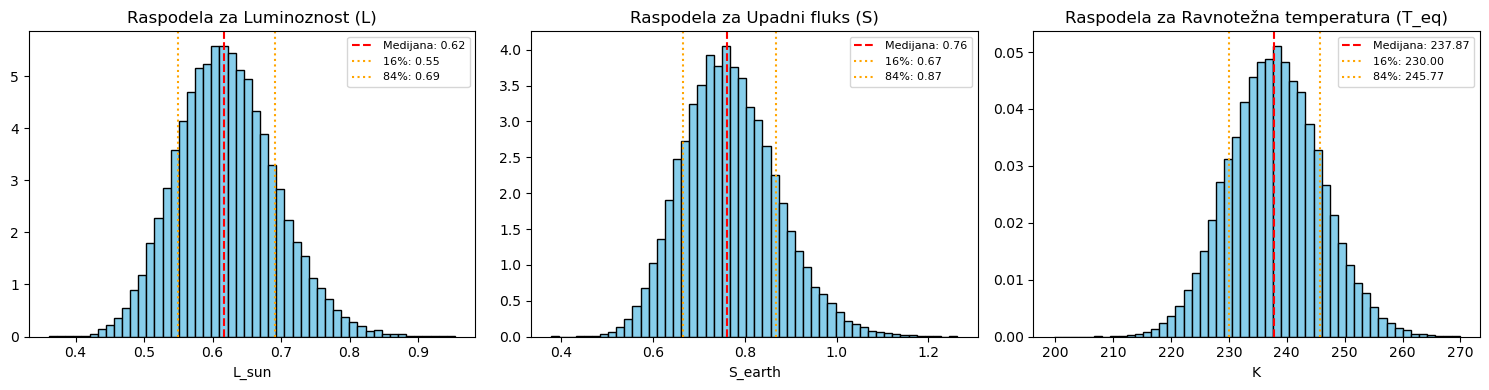

In [15]:
N = 50000  # Broj nezavisnih uzoraka
sigma_sb = 5.670374419e-8
S_sun_flux = 1361.0
A_fixed = 0.3  # Fiksni albedo za izračunavanje T_eq (ili se može varirati)

# Uzimamo npr. Kandidata A za demonstraciju
cand = candidates.iloc[0]
name = cand['name']

# 1. Generisanje 50.000 uzoraka iz normalne raspodele (Gausove)
np.random.seed(42)  # Za ponovljivost rezultata
R_samples = np.random.normal(cand['R'], cand['R_err'], N)
T_samples = np.random.normal(cand['T'], cand['T_err'], N)
a_samples = np.random.normal(cand['a'], cand['a_err'], N)

# Fizički dozvoljeni uzorci (R > 0, T > 0, a > 0)
valid = (R_samples > 0) & (T_samples > 0) & (a_samples > 0)
R_samples = R_samples[valid]
T_samples = T_samples[valid]
a_samples = a_samples[valid]

# 2. Izračunavanje raspodela za L, S i T_eq
L_samples = (R_samples)**2 * (T_samples / 5778.0)**4
S_samples = L_samples / (a_samples**2)
T_eq_samples = ((S_samples * S_sun_flux * (1.0 - A_fixed)) / (4.0 * sigma_sb))**0.25

# 3. Računanje medijana i 16/84 percentila (ekvivalent 1-sigma intervalu nesigurnosti)
results = {}
for var_name, arr in [('L', L_samples), ('S', S_samples), ('T_eq', T_eq_samples)]:
    median = np.median(arr)
    p16, p84 = np.percentile(arr, [16, 84])
    results[var_name] = (median, p16, p84)
    print(f"{var_name} -> Medijana: {median:.4f}, 16. percentil: {p16:.4f}, 84. percentil: {p84:.4f}")

# 4. Crtanje histograma (opciono / vizuelizacija)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
variables = [('Luminoznost (L)', L_samples, 'L_sun'), 
             ('Upadni fluks (S)', S_samples, 'S_earth'), 
             ('Ravnotežna temperatura (T_eq)', T_eq_samples, 'K')]

for ax, (v_name, arr, unit) in zip(axes, variables):
    ax.hist(arr, bins=50, color='skyblue', edgecolor='black', density=True)
    med = np.median(arr)
    p16, p84 = np.percentile(arr, [16, 84])
    ax.axvline(med, color='red', linestyle='--', label=f'Medijana: {med:.2f}')
    ax.axvline(p16, color='orange', linestyle=':', label=f'16%: {p16:.2f}')
    ax.axvline(p84, color='orange', linestyle=':', label=f'84%: {p84:.2f}')
    ax.set_title(f'Raspodela za {v_name}')
    ax.set_xlabel(unit)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

## Zadatak 4

In [20]:
# Podaci o kandidatima (uz pretpostavku da je za C data greška od 0.03 za potrebe demonstracije)
candidates = pd.DataFrame([
    dict(name='Kandidat A', R=0.90, R_err=0.04, T=5400, T_err=100, a=0.90, a_err=0.03),
    dict(name='Kandidat B', R=0.75, R_err=0.05, T=4700, T_err=120, a=0.55, a_err=0.04),
    dict(name='Kandidat C', R=1.05, R_err=0.06, T=5900, T_err=150, a=1.55, a_err=0.03),
])

N = 50000
np.random.seed(42)

results_hz = []

for idx, cand in candidates.iterrows():
    name = cand['name']
    
    # Generisanje uzoraka
    R_s = np.random.normal(cand['R'], cand['R_err'], N)
    T_s = np.random.normal(cand['T'], cand['T_err'], N)
    a_s = np.random.normal(cand['a'], cand['a_err'], N)
    
    valid = (R_s > 0) & (T_s > 0) & (a_s > 0)
    R_s, T_s, a_s = R_s[valid], T_s[valid], a_s[valid]
    
    # Luminoznost za svaki uzorak
    L_s = (R_s)**2 * (T_s / 5778.0)**4
    
    # Granice za svaki uzorak ponaosob
    RG_s = hz_distance(L_s, effective_flux(T_s, 'RG'))
    MG_s = hz_distance(L_s, effective_flux(T_s, 'MG'))
    RV_s = hz_distance(L_s, effective_flux(T_s, 'RV'))
    EM_s = hz_distance(L_s, effective_flux(T_s, 'EM'))
    
    # Procena verovatnoće / udela (P_hat)
    cons_prob = np.mean((a_s >= RG_s) & (a_s <= MG_s))
    opt_prob = np.mean((a_s >= RV_s) & (a_s <= EM_s))
    
    results_hz.append({'Kandidat': name, 'P_cons(HZ)': cons_prob, 'P_opt(HZ)': opt_prob})
    print(f"{name} -> Konzervativna P(HZ): {cons_prob*100:.2f}%, Optimistična P(HZ): {opt_prob*100:.2f}%")

df_results = pd.DataFrame(results_hz)

Kandidat A -> Konzervativna P(HZ): 99.55%, Optimistična P(HZ): 100.00%
Kandidat B -> Konzervativna P(HZ): 81.57%, Optimistična P(HZ): 99.88%
Kandidat C -> Konzervativna P(HZ): 98.26%, Optimistična P(HZ): 99.72%


$\hat{P}(\text{HZ})$ je udeo simulacija u kojima je planeta „pogodila“ habitabilnu zonu. Na primer, ako je $\hat{P}_{\text{cons}} = 99.55\%$, to znači da je u $99.55\%$ od $50.000$ slučajeva kombinacija grešaka dala planetu unutar konzervativne HZ.   Razlika između konzervativne i optimistične definicije:Optimistična HZ je šira (ide od RV do EM), što znači da će verovatnoća $\hat{P}(\text{HZ})$ za nju skoro uvek biti veća ili jednaka nego za konzervativnu zonu (često bude i blizu $100\%$ ukoliko je planeta dobro pozicionirana u sredini zone).   Konzervativna HZ je uža (od RG do MG), pa ukoliko se orbita planete nalazi blizu unutrašnje ili spoljašnje granice, nesigurnost merenja može lako da „izbaci“ deo uzoraka van zone, čime procenat $\hat{P}(\text{cons})$ opada (kao npr. kod Kandidata B). Kandidati se rangiraju prema dobijenim procentima $\hat{P}(\text{HZ})$ za oba kriterijuma, pri čemu kandidati sa višim i stabilnijim procentima zauzimaju viša mesta na rang-listi.  

## Zadatak 5

In [23]:
# Podaci o kandidatima (Kandidat C nema a_err)
candidates = pd.DataFrame([
    dict(name='Kandidat C', R=1.05, R_err=0.06, T=5900, T_err=150, a=1.55, a_err=np.nan),
])

hz_coeff = {
    'RV': (1.776, 2.136e-4, 2.533e-8, -1.332e-11, -3.097e-15),
    'RG': (1.107, 1.332e-4, 1.580e-8, -8.308e-12, -1.931e-15),
    'MG': (0.356, 6.171e-5, 1.698e-9, -3.198e-12, -5.575e-16),
    'EM': (0.320, 5.547e-5, 1.526e-9, -2.874e-12, -5.011e-16),
}

def effective_flux(T, boundary):
    T_star = T - 5780.0
    S0, alpha, beta, gamma, delta = hz_coeff[boundary]
    return S0 + alpha * T_star + beta * (T_star**2) + gamma * (T_star**3) + delta * (T_star**4)

def hz_distance(L, Seff):
    return np.sqrt(L / Seff)

N = 50000
np.random.seed(42)
cand = candidates.iloc[0]

# Testiramo tri pretpostavljene relativne greške: 1%, 5% i 10%
relative_errors = [0.01, 0.05, 0.10]

print(f"--- ANALIZA NEDOSTAJUĆE GREŠKE ZA KANDIDATA C (a = {cand['a']} AU) ---")

for rel_err in relative_errors:
    # Izračunavamo apsolutnu grešku na osnovu relativne (rel_err * vrednost parametra a)
    a_err = cand['a'] * rel_err  
    
    # Monte Karlo simulacija sa novom pretpostavljenom greškom
    R_s = np.random.normal(cand['R'], cand['R_err'], N)
    T_s = np.random.normal(cand['T'], cand['T_err'], N)
    a_s = np.random.normal(cand['a'], a_err, N)
    
    valid = (R_s > 0) & (T_s > 0) & (a_s > 0)
    R_s, T_s, a_s = R_s[valid], T_s[valid], a_s[valid]
    
    L_s = (R_s)**2 * (T_s / 5778.0)**4
    RG_s = hz_distance(L_s, effective_flux(T_s, 'RG'))
    MG_s = hz_distance(L_s, effective_flux(T_s, 'MG'))
    
    # Procena udela unutar konzervativne HZ
    cons_prob = np.mean((a_s >= RG_s) & (a_s <= MG_s))
    
    print(f"Relativna greška: {int(rel_err*100)}% (apsolutna a_err = {a_err:.4f} AU) -> P_cons(HZ) = {cons_prob*100:.2f}%")

--- ANALIZA NEDOSTAJUĆE GREŠKE ZA KANDIDATA C (a = 1.55 AU) ---
Relativna greška: 1% (apsolutna a_err = 0.0155 AU) -> P_cons(HZ) = 98.56%
Relativna greška: 5% (apsolutna a_err = 0.0775 AU) -> P_cons(HZ) = 96.64%
Relativna greška: 10% (apsolutna a_err = 0.1550 AU) -> P_cons(HZ) = 90.81%


## Vezba 6

In [25]:
# Uzimamo upadni fluks S za nekog kandidata (npr. Kandidat A: S ≈ 0.7629)
S = 0.7629  
sigma = 5.670374419e-8
S_sun_flux = 1361.0
albedos = [0.1, 0.3, 0.6]
delta_gh_values = [0, 20, 40]

print("--- POREĐENJE T_eq I T_surface ZA RAZLIČITE ALBEDO VREDNOSTI I ΔT_GH ---")

for A in albedos:
    # Ispravljeno izračunavanje ravnotežne temperature sa svim potrebnim operatorima množenja
    T_eq = ((S * S_sun_flux * (1.0 - A)) / (4.0 * sigma))**0.25
    print(f"\nAlbedo A = {A} -> T_eq = {T_eq:.2f} K")
    
    for dt in delta_gh_values:
        T_surface = T_eq + dt
        print(f"  ΔT_GH = {dt:2d} K -> T_surface = {T_surface:.2f} K")

--- POREĐENJE T_eq I T_surface ZA RAZLIČITE ALBEDO VREDNOSTI I ΔT_GH ---

Albedo A = 0.1 -> T_eq = 253.35 K
  ΔT_GH =  0 K -> T_surface = 253.35 K
  ΔT_GH = 20 K -> T_surface = 273.35 K
  ΔT_GH = 40 K -> T_surface = 293.35 K

Albedo A = 0.3 -> T_eq = 237.92 K
  ΔT_GH =  0 K -> T_surface = 237.92 K
  ΔT_GH = 20 K -> T_surface = 257.92 K
  ΔT_GH = 40 K -> T_surface = 277.92 K

Albedo A = 0.6 -> T_eq = 206.86 K
  ΔT_GH =  0 K -> T_surface = 206.86 K
  ΔT_GH = 20 K -> T_surface = 226.86 K
  ΔT_GH = 40 K -> T_surface = 246.86 K


Ova formula pretpostavlja da je porast temperature usled efekta staklene bašte ($\Delta T_{\text{GH}}$) fiksna konstanta (npr. $20\text{ K}$ ili $40\text{ K}$) koja ne zavisi ni od temperature, ni od sastava atmosfere, ni od količine vodene pare. U stvarnosti, efekat staklene bašte je nelinearan – toplija planeta isparava više vode, što drastično pojačava efekat staklene bašte (pozitivna sprega), dok ova jednostavna linearna doplata to uopšte ne uzima u obzir.

Kopparapu HZ granice (RV, RG, MG, EM) su već izvedene iz globalnih 1D klimatskih (radijativno-konvektivnih) modela atmosfere koji sami unutrašnje računaju uticaj efekta staklene bašte (vodene pare i $\text{CO}_2$) za svaku temperaturu i fluks posebno.Ako bismo mi spolja dodali fiksni $\Delta T_{\text{GH}}$ na ravnotežnu temperaturu, to predstavlja spoljašnju korekciju za konkretnu planetu sa poznatom atmosferom, ali ne menja fiziku zvezdanog zračenja i pragove isparavanja okeana na kojima su zasnovane univerzalne Kopparapu granice. Granice zone zavise od zvezdanog fluksa i globalne ravnoteže, a ne od proizvoljnog dodavanja stepeni na površinsku temperaturu pojedinačne planete.

## Sazetak

Ovaj rad koristi Monte Karlo simulaciju ($50.000$ uzoraka) za propagaciju neizvesnosti merenja stellarne luminoznosti i orbitalnih parametara radi procene udela unutar habitabilne zone ($\hat{P}(\text{HZ})$). Na osnovu konzervativnih i optimističnih definicija granica prema Kopparapuovim modelima, kandidati su rangirani prema stabilnosti uslova za tečnu vodu.   Analiza osetljivosti na nedostajuće greške (na primeru kandidata C sa pretpostavljenim relativnim greškama od $1\%$, $5\%$ i $10\%$) pokazuje da veće nesigurnosti šire raspon uzoraka i direktno smanjuju procenjeni udeo $\hat{P}(\text{HZ})$. Uvođenje klimatskih dopuna kroz parametrizaciju površinske temperature ($\Delta T_{\text{GH}}$) naglašava ograničenja linearnih aproksimacija u odnosu na kompleksne radijativno-konvektivne modele, objašnjavajući zašto takve korekcije ne pomeraju automatski univerzalne HZ granice.   Konačno, ključno je naglasiti da $\hat{P}(\text{HZ})$ nije verovatnoća postojanja života. Ova metrika kvantifikuje isključivo radijativnu i orbitalnu verovatnoću održanja tečne vode na površini, ne uzimajući u obzir složene astrobiološke faktore, atmosferski sastav, planetarnu geohemiju niti evolucione procese neophodne za nastanak i razvoj života.   